# A2 E1/E2 — Nhận dạng biển số: CRNN-BiLSTM-CTC vs PDLPR-inspired

Notebook khung cho **hai phương pháp nhận dạng** dùng chung dữ liệu, input, augmentation, loss, giải mã và metric, chỉ khác kiến trúc. Đây là phần so sánh ≥ 2 phương pháp mà đề A2 (mục 4.1) yêu cầu; E0 (YOLOv5s) cung cấp detector.

| Mã | Mô hình | Ý tưởng |
|---|---|---|
| **E1** | CRNN: CNN → BiLSTM 2 lớp → CTC | Baseline RNN, tương ứng nhóm "RNN + attention" mà paper phê bình vì không song song hóa |
| **E2** | PDLPR-inspired: IGFE (Focus + RESBLOCK + ConvDownSampling) → Encoder 3 unit (multi-head attention) → Parallel Decoder 3 unit → CTC | Tái hiện theo mô tả của Tao et al., *Sensors* 24 (2024), 2791 |

**Công bằng khi so sánh:** cùng crop biển số, cùng input 48×144, cùng augmentation, cùng CTC loss và greedy decoding, cùng seed/epoch/optimizer/split. Số tham số và tốc độ được báo cáo kèm theo vì hai mô hình có kích thước rất khác nhau.

## Những điểm E2 KHÔNG giống paper (phải nêu trong báo cáo, không tuyên bố "reproduce PDLPR")
1. **Decoder không tự hồi quy.** Hình 7 của paper vẽ đầu vào "Output shifted right" (kiểu teacher forcing) nhưng văn bản nói huấn luyện bằng CTC; hai điều này mâu thuẫn. Ở đây decoder dùng 18 query học được, self-attention không mask, cross-attention vào đặc trưng encoder, huấn luyện bằng CTC, nên chạy hoàn toàn song song khi suy luận. Biến thể `e2_pdlpr_memq` lấy query từ chính đặc trưng ảnh.
2. **Số kênh của IGFE** paper không nêu; dùng 64/128/512 (đầu ra 512×6×18 khớp paper).
3. **CNN BLOCK1/2 của encoder:** paper ghi kernel=1, padding=1, nhưng padding=1 với kernel 1 làm đổi kích thước không gian và mâu thuẫn với n=108 (6×18); ở đây padding=0.
4. **CNN BLOCK3/4 của decoder** (tham số stride/kernel khó hiểu) được thay bằng một conv kernel (6,1) nén chiều cao 6 → 1, cho 18 token.
5. **Residual của Add&Norm** trong encoder: cộng đầu vào unit với đầu ra unit rồi LayerNorm (paper mô tả không rõ). Slope LeakyReLU 0.1, dropout 0.1, positional encoding sin-cos 2D là lựa chọn của nhóm.
6. **Lịch huấn luyện ngắn hơn nhiều** (30 epoch so với 1000 của paper) và dữ liệu là tập CCPD rút gọn của dự án (`yolo_detection.zip`), nên không so trực tiếp con số với bảng của paper.

## Dữ liệu và luồng chạy trên Colab
Dùng **cùng bộ dữ liệu `yolo_detection.zip` như E0**: tải từ Google Cloud Storage về `/content`, giải nén local (đọc ảnh từ đĩa local nên nhanh hơn nhiều so với Drive). Drive chỉ dùng để lưu **checkpoint và kết quả**, vì `/content` mất khi phiên Colab bị ngắt.

- **Ảnh + box:** `images/{train,val,test}` và `labels/{train,val,test}` (YOLO, 1 lớp). Crop biển số cắt theo box trong file label của E0, nên nhất quán với detector; nếu thiếu label thì dùng box trong tên file.
- **Nhãn ký tự:** parse từ **tên file CCPD gốc** (`area-tilt-bbox-vertices-plate_idx-brightness-blur.jpg`). Nếu file trong zip đã bị đổi tên, cell kiểm tra sẽ dừng và báo rõ; khi đó cần sửa `parse_ccpd_name` hoặc cung cấp `manifest.csv` có tên gốc.
- **Subset (DB/FN/Rotate/Tilt/Weather/Challenge):** lấy từ thư mục con `images/<split>/<subset>/`; nếu phẳng thì lấy từ tiền tố tên file `ccpd_<subset>__...`; nếu không có thì tra `manifest.csv` (cột `subset`, `output_path`); nếu cũng không có thì gom vào nhóm `(root)` và phân tích theo subset chỉ còn một nhóm.
- **`best.pt` của E0:** chỉ cần cho pipeline end-to-end (mục 11). E0 đang ghi vào `/content/outputs/...` nên **hãy copy lên Drive** trước khi ngắt phiên; notebook này tự tìm ở cả hai nơi.

Notebook không ghi vào dataset; crop được ghi vào `/content/plate_crops`. Mọi bước nặng có cờ `RUN_*`; test chỉ chạy một lần sau khi đã chọn model theo validation.


## 0. Môi trường

In [6]:
import os, sys, json, csv, math, re, time, random, platform, shutil, itertools
from pathlib import Path
from collections import Counter, defaultdict
try:
    from google.colab import drive
    drive.mount('/content/drive'); IN_COLAB=True
except ImportError:
    IN_COLAB=False; print('Không chạy trong Colab: hãy sửa đường dẫn ở cell cấu hình.')
import numpy as np, pandas as pd
from PIL import Image
try:
    import torch, torch.nn as nn, torch.nn.functional as F
    from torch.utils.data import Dataset, DataLoader
    DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print({'python':sys.version.split()[0],'torch':torch.__version__,'device':str(DEVICE),
           'gpu':torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else None})
except ImportError:
    torch=None; print('PyTorch chưa có. Cài torch/torchvision trước khi chạy các cell mô hình.')
try: display
except NameError: display=print

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{'python': '3.13.16', 'torch': '2.14.1+cu130', 'device': 'cuda', 'gpu': 'NVIDIA L4'}


## 1. Cấu hình trung tâm
Đường dẫn dataset/GCS khớp notebook E0 (cùng bucket, cùng `yolo_detection.zip`). Các cờ `RUN_*` và danh sách `TRAIN_LIST`/`TEST_LIST` mặc định rỗng/tắt.

In [21]:
# ===== Đường dẫn =====
DRIVE_PROJECT = Path('/content/drive/MyDrive/ComputerVision/A2')    # chỉ để lưu checkpoint/kết quả (bền qua phiên Colab)

# Dataset: tải từ Google Cloud Storage, giải nén local (giống notebook E0)
GCS_BUCKET        = 'hoctran-dataset-bucket'
GCS_ZIP_NAME      = 'yolo_detection.zip'
LOCAL_ZIP         = Path('/content')/GCS_ZIP_NAME
LOCAL_DATA_PARENT = Path('/content/dataset')
DATASET_DIR       = LOCAL_DATA_PARENT/'yolo_detection'               # được dò lại tự động sau khi giải nén
KEEP_ZIP          = False                                            # xóa file zip sau khi giải nén để tiết kiệm đĩa

# Crop biển số (local, dựng lại được từ dataset nên không cần lưu Drive)
CROPS_DIR   = Path('/content/plate_crops')
DATA_ROOT   = CROPS_DIR

# Nhãn phụ (tùy chọn): manifest dùng để lấy subset khi images/test không chia thư mục con
MANIFEST_CANDIDATES = [DATASET_DIR/'manifest.csv', LOCAL_DATA_PARENT/'manifest.csv',
                       DRIVE_PROJECT/'CCPD_reduced'/'manifest.csv']

# Kết quả huấn luyện (trên Drive)
OUTPUT_ROOT = DRIVE_PROJECT/'outputs'/'recognition_e1_e2'
MODELS_DIR, RESULTS_DIR = OUTPUT_ROOT/'models', OUTPUT_ROOT/'results'

# Detector E0 (chỉ cần cho end-to-end). E0 ghi vào /content/outputs; nếu đã copy lên Drive thì dùng bản Drive
YOLOV5_DIR = Path('/content/yolov5')
E0_BEST_PT_CANDIDATES = [
    Path('/content/outputs/yolov5s_e0/runs/yolov5s_ccpd_e0/weights/best.pt'),
    DRIVE_PROJECT/'outputs'/'yolov5s_e0'/'runs'/'yolov5s_ccpd_e0'/'weights'/'best.pt',
]
def resolve_e0_best():
    return next((p for p in E0_BEST_PT_CANDIDATES if p.is_file()), E0_BEST_PT_CANDIDATES[0])
E0_BEST_PT = resolve_e0_best()

SPLITS=('train','val','test'); IMAGE_EXTENSIONS={'.jpg','.jpeg','.png','.bmp','.webp'}
IMG_H, IMG_W = 48, 144          # input chung cho E1 và E2 (khớp paper)
CROP_MARGIN  = 0.10             # nới box GT mỗi phía theo tỉ lệ cạnh box
BATCH_SIZE, EPOCHS, LR = 128, 30, 1e-3
EARLY_STOP_PATIENCE = 8
WORKERS, SEED, USE_AMP = 2, 42, True   # dataset ở đĩa local nên có thể thử WORKERS=4 nếu Colab có đủ CPU
MAX_TRAIN_SAMPLES = None        # số nguyên để chạy thử nhanh
IOU_E2E, IOU_DET = 0.6, 0.7     # tiêu chí paper: pipeline đúng khi IoU>0.6 và đúng mọi ký tự; detection đúng khi IoU>0.7

# Cờ opt-in
RUN_DOWNLOAD    = True          # tải + giải nén từ GCS (tự bỏ qua nếu dataset đã có ở /content/dataset)
RUN_BUILD_CROPS = True          # dựng crop biển số (bỏ qua crop đã có)
RUN_MODEL_SELFTEST = True       # chỉ kiểm tra shape/backward bằng dữ liệu giả, không đụng dataset
RUN_SMOKE_TEST  = True
SMOKE_MODELS    = ['e2_pdlpr','e2_pdlpr_memq']
TRAIN_LIST      = ['e2_pdlpr','e2_pdlpr_memq']            # vd ['e1_crnn','e2_pdlpr']
TEST_LIST       = ['e1_crnn','e2_pdlpr','e2_pdlpr_memq']            # chỉ điền sau khi đã chốt model theo validation
RUN_E2E         = True
E2E_MODELS      = ['e1_crnn','e2_pdlpr','e2_pdlpr_memq']
E2E_MAX_PER_SUBSET = None

def require(cond,msg):
    if not cond: raise RuntimeError(msg)
def set_seed(s):
    random.seed(s); np.random.seed(s)
    if torch is not None:
        torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)
print('GCS:',f'gs://{GCS_BUCKET}/{GCS_ZIP_NAME}','\nDataset (local):',DATASET_DIR,'\nCrops (local):',CROPS_DIR,'\nOutput (Drive):',OUTPUT_ROOT,'\nE0 best.pt:',E0_BEST_PT,'(có)' if E0_BEST_PT.is_file() else '(chưa thấy)')


GCS: gs://hoctran-dataset-bucket/yolo_detection.zip 
Dataset (local): /content/dataset/yolo_detection 
Crops (local): /content/plate_crops 
Output (Drive): /content/drive/MyDrive/ComputerVision/A2/outputs/recognition_e1_e2 
E0 best.pt: /content/drive/MyDrive/ComputerVision/A2/outputs/yolov5s_e0/runs/yolov5s_ccpd_e0/weights/best.pt (có)


## 1b. Tải dataset từ Google Cloud Storage và giải nén (local)
Tải `yolo_detection.zip` từ bucket (cùng bucket với E0), giải nén vào `/content/dataset/`, rồi tự dò thư mục có `images/{train,val,test}` + `labels/{train,val,test}`. Nếu dataset đã được giải nén ở phiên này thì **bỏ qua**, không tải lại. Dataset gốc không bị sửa.

In [8]:
import zipfile
import subprocess

def find_yolo_root(base,max_depth=3):
    base=Path(base)
    def ok(d): return all((d/'images'/s).is_dir() and (d/'labels'/s).is_dir() for s in SPLITS)
    if not base.is_dir(): return None
    if ok(base):
        return base
    level=[base]
    for _ in range(max_depth):
        level=[c for d in level for c in d.iterdir() if c.is_dir()]
        for d in level:
            if ok(d): return d
    return None

if RUN_DOWNLOAD:
    root=find_yolo_root(LOCAL_DATA_PARENT)
    if root is None:
        from google.colab import auth
        from google.cloud import storage
        auth.authenticate_user(); print('Đã xác thực Google Cloud.')
        LOCAL_ZIP.parent.mkdir(parents=True,exist_ok=True); LOCAL_DATA_PARENT.mkdir(parents=True,exist_ok=True)
        print(f'Đang tải gs://{GCS_BUCKET}/{GCS_ZIP_NAME} ...'); t0=time.time()
        storage.Client().bucket(GCS_BUCKET).blob(GCS_ZIP_NAME).download_to_filename(str(LOCAL_ZIP))
        print(f'Tải xong ({LOCAL_ZIP.stat().st_size/1e9:.2f} GB, {time.time()-t0:.0f}s). Đang giải nén ...')
        if shutil.which('unzip'):
            r=subprocess.run(['unzip','-q','-o',str(LOCAL_ZIP),'-d',str(LOCAL_DATA_PARENT)])
            require(r.returncode==0,'unzip lỗi (thử lại hoặc kiểm tra dung lượng đĩa Colab).')
        else:
            with zipfile.ZipFile(LOCAL_ZIP) as z: z.extractall(LOCAL_DATA_PARENT)
        if not KEEP_ZIP: LOCAL_ZIP.unlink(missing_ok=True)
        root=find_yolo_root(LOCAL_DATA_PARENT)
    else: print('Dataset đã có ở phiên này, bỏ qua tải:',root)
    require(root is not None,f'Không thấy cấu trúc images/{{train,val,test}} + labels/{{train,val,test}} trong {LOCAL_DATA_PARENT}. Kiểm tra cấu trúc thư mục trong file zip.')
    DATASET_DIR=root
    MANIFEST_CANDIDATES=[DATASET_DIR/'manifest.csv']+[p for p in MANIFEST_CANDIDATES if p!=DATASET_DIR/'manifest.csv']
    print('DATASET_DIR =',DATASET_DIR)
    print({s:sum(1 for q in (DATASET_DIR/'images'/s).rglob('*') if q.suffix.lower() in IMAGE_EXTENSIONS) for s in SPLITS})
else: print('Tải dataset đang TẮT (RUN_DOWNLOAD=False). DATASET_DIR =',DATASET_DIR,'| tồn tại:',DATASET_DIR.is_dir())

Dataset đã có ở phiên này, bỏ qua tải: /content/dataset/yolo_detection
DATASET_DIR = /content/dataset/yolo_detection
{'train': 18000, 'val': 2000, 'test': 5000}


## 2. Nhãn CCPD và từ điển ký tự
Tên file CCPD gồm 7 trường ngăn bởi `-`: diện tích, góc nghiêng, **box** `x1&y1_x2&y2`, 4 đỉnh, **chỉ số ký tự** (7 số: tỉnh, chữ cái, 5 ký tự), độ sáng, độ mờ. Ký tự `O` trong các bảng tra là ô giữ chỗ (biển không đủ 7 ký tự) nên mẫu chứa nó bị loại và đếm lại.

In [9]:
PROVINCES=['皖','沪','津','渝','冀','晋','蒙','辽','吉','黑','苏','浙','京','闽','赣','鲁','豫','鄂','湘','粤','桂','琼','川','贵','云','藏','陕','甘','青','宁','新','警','学','O']
ALPHABETS=list('ABCDEFGHJKLMNPQRSTUVWXYZ')+['O']
ADS=list('ABCDEFGHJKLMNPQRSTUVWXYZ0123456789')+['O']
VOCAB=PROVINCES[:-1]+list('ABCDEFGHJKLMNPQRSTUVWXYZ')+list('0123456789')
BLANK=0
CHAR2IDX={c:i+1 for i,c in enumerate(VOCAB)}; IDX2CHAR={i:c for c,i in CHAR2IDX.items()}
NUM_CLASSES=len(VOCAB)+1

def parse_ccpd_name(name):
    """Trả về dict {text,bbox,...} hoặc None nếu tên không đúng định dạng CCPD/ chứa ô giữ chỗ."""
    f=Path(name).stem.split('-')
    if len(f)!=7: return None
    try:
        (x1,y1),(x2,y2)=[tuple(int(v) for v in p.split('&')) for p in f[2].split('_')]
        idx=[int(v) for v in f[4].split('_')]
        if len(idx)!=7: return None
        chars=[PROVINCES[idx[0]],ALPHABETS[idx[1]]]+[ADS[i] for i in idx[2:]]
    except (ValueError,IndexError): return None
    text=''.join(chars)
    if 'O' in chars or any(c not in CHAR2IDX for c in text): return None
    return {'text':text,'bbox':(x1,y1,x2,y2),'brightness':int(f[5]),'blur':int(f[6])}

def crop_box(bbox,w,h,margin):
    x1,y1,x2,y2=bbox; mx,my=(x2-x1)*margin,(y2-y1)*margin
    return (max(0,int(x1-mx)),max(0,int(y1-my)),min(w,int(x2+mx)),min(h,int(y2+my)))
def encode_text(t): return [CHAR2IDX[c] for c in t]
def ctc_collapse(ids,blank=BLANK):
    out=[];prev=None
    for i in ids:
        if i!=prev and i!=blank: out.append(int(i))
        prev=i
    return ''.join(IDX2CHAR[i] for i in out)
def ascii_label(t): return f'p{PROVINCES.index(t[0])}|{t[1:]}'   # tiêu đề ảnh không cần font CJK

# self-test: ví dụ trong tài liệu CCPD
_ex='025-95_113-154&383_386&473-386&473_177&454_154&383_363&402-0_0_22_27_27_33_16-37-15.jpg'
_r=parse_ccpd_name(_ex); assert _r and _r['text']=='皖AY339S' and _r['bbox']==(154,383,386,473),_r
assert parse_ccpd_name('IMG_0001.jpg') is None
assert ctc_collapse([0,5,5,0,5,7,7,0])==IDX2CHAR[5]+IDX2CHAR[5]+IDX2CHAR[7]
print('Số lớp (gồm blank):',NUM_CLASSES,'| parse ví dụ:',_r['text'])

Số lớp (gồm blank): 68 | parse ví dụ: 皖AY339S


## 3. Metric (không phụ thuộc torch)
Báo cáo exact-match toàn biển số, exact-match **không tính ký tự tỉnh** (như Bảng 5 của paper), độ chính xác riêng ký tự tỉnh và độ chính xác theo ký tự (1 − tổng khoảng cách chỉnh sửa / tổng ký tự GT).

In [10]:
def edit_distance(a,b):
    prev=list(range(len(b)+1))
    for i,ca in enumerate(a,1):
        cur=[i]
        for j,cb in enumerate(b,1): cur.append(min(prev[j]+1,cur[j-1]+1,prev[j-1]+(ca!=cb)))
        prev=cur
    return prev[-1]

def compute_metrics(preds,gts,subsets=None):
    n=len(gts)
    if n==0: return {'n':0},{}
    ex=sum(p==g for p,g in zip(preds,gts)); exn=sum(p[1:]==g[1:] for p,g in zip(preds,gts))
    pv=sum(p[:1]==g[:1] for p,g in zip(preds,gts))
    ed=sum(edit_distance(p,g) for p,g in zip(preds,gts)); ch=sum(len(g) for g in gts)
    out={'n':n,'exact':ex/n,'exact_no_province':exn/n,'province_acc':pv/n,'char_acc':max(0.0,1-ed/max(ch,1))}
    by={}
    if subsets is not None:
        for s in sorted(set(subsets)):
            ids=[i for i,x in enumerate(subsets) if x==s]
            by[s]={'n':len(ids),'exact':sum(preds[i]==gts[i] for i in ids)/len(ids),
                   'exact_no_province':sum(preds[i][1:]==gts[i][1:] for i in ids)/len(ids)}
    return out,by

def box_iou_xyxy(a,b):
    ix1,iy1=max(a[0],b[0]),max(a[1],b[1]); ix2,iy2=min(a[2],b[2]),min(a[3],b[3])
    inter=max(0,ix2-ix1)*max(0,iy2-iy1)
    aa=max(0,a[2]-a[0])*max(0,a[3]-a[1]); ab=max(0,b[2]-b[0])*max(0,b[3]-b[1])
    return inter/max(aa+ab-inter,1e-12)

assert edit_distance('abc','abd')==1 and edit_distance('','ab')==2
_m,_b=compute_metrics(['皖AY339S','皖AY339X'],['皖AY339S','皖AY339S'],['DB','DB']); assert _m['exact']==0.5 and _b['DB']['n']==2
assert abs(box_iou_xyxy((0,0,10,10),(0,0,10,5))-0.5)<1e-9
print('Metric self-test OK')

Metric self-test OK


## 4. Kiểm tra tên file và dựng crop biển số (opt-in)
Cell đầu **chỉ đọc**: lấy mẫu tên file trong `images/<split>` và báo tỉ lệ parse được (cảnh báo nếu dưới 99%; cell dựng crop dừng nếu dưới 90%, vì khi đó nhiều khả năng tên file đã bị đổi; phần dưới 100% còn lại là biển có ô giữ chỗ `O`, bị loại và đếm lại). Nếu tên file không phải tên CCPD mà có `manifest.csv` chứa tên gốc, cell sẽ thử tra tên gốc từ manifest.

Cell dựng crop đọc ảnh trong `DATASET_DIR`, cắt theo box trong **file label YOLO** (cùng nguồn với E0) cộng `CROP_MARGIN`, ghi vào `CROPS_DIR` cùng `labels.csv` và `crops_meta.json`. Chạy lại được sau khi Colab ngắt: crop đã có sẽ bỏ qua. Train/val/test giữ đúng split của dataset, nên không rò rỉ so với detector E0.

In [11]:
def image_paths(root):
    return sorted(p for p in root.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS) if root.is_dir() else []
def subset_of(path,split_root):
    rel=path.relative_to(split_root); return rel.parts[0] if len(rel.parts)>1 else '(root)'
def subset_from_prefix(stem):
    m=re.match(r'^ccpd_([A-Za-z0-9]+(?:_[A-Za-z0-9]+)*?)__',stem); return m.group(1) if m else None
def resolve_subset(p,split_root):
    # Thứ tự ưu tiên: thư mục con -> tiền tố tên file 'ccpd_<subset>__' -> manifest -> '(root)'
    s=subset_of(p,split_root)
    if s!='(root)': return s
    return subset_from_prefix(p.stem) or SUBSET_MAP.get(p.stem) or '(root)'

def load_manifest_maps():
    # Trả về (stem -> subset, stem -> tên file gốc). Chỉ đọc; rỗng nếu không có manifest phù hợp.
    sub_map,name_map={},{}
    mp=next((p for p in MANIFEST_CANDIDATES if p.is_file()),None)
    if mp is None: return sub_map,name_map,None
    try: m=pd.read_csv(mp,dtype=str)
    except Exception as e: print('Không đọc được manifest',mp,e); return sub_map,name_map,None
    if 'output_path' in m.columns:
        stems=m['output_path'].astype(str).map(lambda x:Path(x).stem)
        if 'subset' in m.columns: sub_map=dict(zip(stems,m['subset'].astype(str)))
        for col in ('source_path','src_path','original_path','input_path','src','source','orig_name','original_name','filename'):
            if col in m.columns: name_map=dict(zip(stems,m[col].astype(str).map(lambda x:Path(x).name))); break
    return sub_map,name_map,mp
SUBSET_MAP,NAME_MAP,MANIFEST_USED=load_manifest_maps()
print('Manifest:',MANIFEST_USED,'| tra subset:',len(SUBSET_MAP),'| tra tên gốc:',len(NAME_MAP))

def ccpd_info(p):
    info=parse_ccpd_name(p.name)
    if info is None and p.stem in NAME_MAP: info=parse_ccpd_name(NAME_MAP[p.stem])
    return info
def read_yolo_box(label_path,w,h):
    # Lấy box lớn nhất trong file label YOLO -> (x1,y1,x2,y2) pixel; None nếu thiếu/rỗng/sai.
    try:
        best=None
        for line in label_path.read_text().splitlines():
            v=line.split()
            if len(v)!=5: continue
            _,x,y,bw,bh=map(float,v); b=((x-bw/2)*w,(y-bh/2)*h,(x+bw/2)*w,(y+bh/2)*h)
            if best is None or bw*bh>(best[2]-best[0])*(best[3]-best[1]): best=b
        return best
    except OSError: return None

def name_parse_check(n=300):
    rep={}; rng=random.Random(SEED)
    for s in SPLITS:
        root=DATASET_DIR/'images'/s
        if not root.is_dir(): rep[s]={'exists':False}; continue
        ps=image_paths(root); ps=rng.sample(ps,min(n,len(ps)))
        ok=sum(ccpd_info(p) is not None for p in ps)
        rep[s]={'sampled':len(ps),'parse_ok':ok,'rate':ok/len(ps) if ps else None,'example':ps[0].name if ps else None}
    return rep
if DATASET_DIR.is_dir():
    NAME_CHECK=name_parse_check(); print(json.dumps(NAME_CHECK,ensure_ascii=False,indent=2))
    bad=[s for s,r in NAME_CHECK.items() if not r.get('exists',True) or (r.get('rate') or 0)<0.99]
    if bad: print('CẢNH BÁO: split',bad,'có tỉ lệ parse tên <99% hoặc không tồn tại. Tên file có thể đã bị đổi; sửa parse_ccpd_name hoặc cung cấp manifest có tên gốc trước khi dựng crop.')
    troot=DATASET_DIR/'images'/'test'
    if troot.is_dir():
        tp=image_paths(troot); tsub=Counter(resolve_subset(p,troot) for p in tp)
        print('Subset của test:',dict(tsub))
        if SUBSET_MAP and not any(p.stem in SUBSET_MAP for p in tp[:200]):
            print('Ghi chú: stem của manifest KHÔNG khớp tên file trong dataset. Ví dụ manifest:',list(SUBSET_MAP)[:2],'| ví dụ dataset:',[p.stem for p in tp[:2]])
        if set(tsub)=={'(root)'}: print('CẢNH BÁO: không xác định được subset của test (không có thư mục con, tiền tố tên file hay manifest khớp). Bảng theo subset sẽ chỉ có nhóm "(root)".')
else: print('DATASET_DIR chưa có (chạy mục 1b trước):',DATASET_DIR)

Manifest: /content/drive/MyDrive/ComputerVision/A2/CCPD_reduced/manifest.csv | tra subset: 24942 | tra tên gốc: 24942
{
  "train": {
    "sampled": 300,
    "parse_ok": 300,
    "rate": 1.0,
    "example": "013292624521-93_82-204&453_416&537-424&538_201&528_190&453_413&463-0_0_23_17_30_24_33-131-47.jpg"
  },
  "val": {
    "sampled": 300,
    "parse_ok": 300,
    "rate": 1.0,
    "example": "0452586206897-103_65-273&518_566&673-577&688_282&608_268&510_563&590-0_0_7_27_33_32_31-45-23.jpg"
  },
  "test": {
    "sampled": 300,
    "parse_ok": 300,
    "rate": 1.0,
    "example": "ccpd_rotate__0425-21_19-285&442_475&629-475&557_289&629_285&514_471&442-0_0_2_8_26_25_29-152-55.jpg"
  }
}
Subset của test: {'blur': 500, 'challenge': 2500, 'db': 500, 'fn': 500, 'rotate': 500, 'tilt': 500}
Ghi chú: stem của manifest KHÔNG khớp tên file trong dataset. Ví dụ manifest: ['0029-1_1-323&513_408&542-408&540_323&542_323&515_408&513-0_0_33_26_30_23_32-118-4', '0033-0_3-352&473_440&505-438&505_352&505_354

In [12]:
if RUN_BUILD_CROPS:
    require(DATASET_DIR.is_dir(),f'Không thấy {DATASET_DIR}. Chạy mục 1b trước.')
    require(all((r.get('rate') or 0)>=0.90 for r in NAME_CHECK.values()),'Tỉ lệ parse tên file <90%: nhiều khả năng tên file đã bị đổi. Xem cell kiểm tra ở trên.')
    try: from tqdm.auto import tqdm
    except ImportError: tqdm=lambda x,**k:x
    CROPS_DIR.mkdir(parents=True,exist_ok=True); rows=[]; stats=Counter()
    for split in SPLITS:
        iroot,lroot=DATASET_DIR/'images'/split,DATASET_DIR/'labels'/split
        for p in tqdm(image_paths(iroot),desc=split):
            info=ccpd_info(p)
            if info is None: stats[f'{split}_skipped_parse']+=1; continue
            sub=resolve_subset(p,iroot)
            rel=Path(split)/sub.replace('(root)','_root')/(p.stem+'.jpg'); out=CROPS_DIR/rel
            try:
                with Image.open(p) as im0:
                    w,h=im0.size                                   # đọc header, rẻ
                    bb=read_yolo_box(lroot/p.relative_to(iroot).with_suffix('.txt'),w,h); box_src='label'
                    if bb is None: bb=tuple(float(v) for v in info['bbox']); box_src='name'; stats[f'{split}_box_from_name']+=1
                    elif box_iou_xyxy(bb,info['bbox'])<0.5: stats[f'{split}_label_vs_name_iou<0.5']+=1
                    cb=crop_box(bb,w,h,CROP_MARGIN)
                    if cb[2]-cb[0]<8 or cb[3]-cb[1]<4: stats[f'{split}_skipped_bad_box']+=1; continue
                    if not out.exists():
                        out.parent.mkdir(parents=True,exist_ok=True); im0.convert('RGB').crop(cb).save(out,quality=95)
            except Exception as e: stats[f'{split}_skipped_error']+=1; continue
            rows.append({'split':split,'subset':sub,'crop_rel':rel.as_posix(),'src_rel':p.relative_to(DATASET_DIR).as_posix(),
                         'text':info['text'],'x1':round(bb[0],1),'y1':round(bb[1],1),'x2':round(bb[2],1),'y2':round(bb[3],1),
                         'box_src':box_src,'brightness':info['brightness'],'blur':info['blur']})
    df=pd.DataFrame(rows); df.to_csv(CROPS_DIR/'labels.csv',index=False,encoding='utf-8-sig')
    (CROPS_DIR/'crops_meta.json').write_text(json.dumps({'margin':CROP_MARGIN,'rows':len(df),'skipped':dict(stats),'dataset':str(DATASET_DIR),'created':time.strftime('%Y-%m-%d %H:%M:%S')},indent=2))
    print('Đã ghi',len(df),'dòng vào',CROPS_DIR,'. Bỏ qua/ghi chú:',dict(stats))
else: print('Dựng crop đang TẮT (RUN_BUILD_CROPS=False).')

train:   0%|          | 0/18000 [00:00<?, ?it/s]

val:   0%|          | 0/2000 [00:00<?, ?it/s]

test:   0%|          | 0/5000 [00:00<?, ?it/s]

Đã ghi 25000 dòng vào /content/plate_crops . Bỏ qua/ghi chú: {}


## 5. EDA cho bài toán nhận dạng
Thống kê số mẫu theo split/subset, phân bố ký tự tỉnh và ảnh mẫu. Paper cảnh báo ký tự "皖" chiếm hơn 95% CCPD, nên con số này quyết định cách đọc kết quả (có/không tính ký tự tỉnh).

Tổng mẫu: 25000 | thiếu file crop (kiểm 2000 đầu): 0


split,test,train,val
subset,,,
blur,500,0,0
ccpd_base,0,18000,2000
challenge,2500,0,0
db,500,0,0
fn,500,0,0
rotate,500,0,0
tilt,500,0,0


train tỉnh phổ biến nhất: {'皖': 0.9596, '苏': 0.0171, '浙': 0.0059, '沪': 0.0028, '豫': 0.0019}
val tỉnh phổ biến nhất: {'皖': 0.9635, '苏': 0.013, '浙': 0.0065, '沪': 0.0035, '冀': 0.002}
test tỉnh phổ biến nhất: {'皖': 0.8888, '苏': 0.0272, '浙': 0.0134, '沪': 0.0086, '鄂': 0.0064}
Độ dài nhãn: {7: 25000}


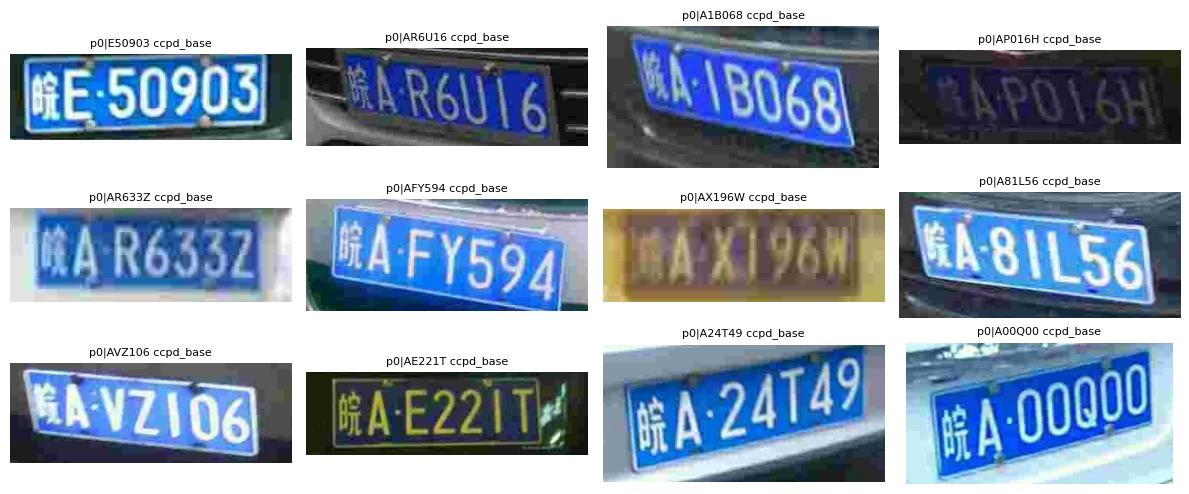

In [13]:
def load_labels():
    p=DATA_ROOT/'labels.csv'; require(p.is_file(),f'Chưa có {p}. Bật RUN_BUILD_CROPS và chạy cell dựng crop.')
    return pd.read_csv(p,encoding='utf-8-sig',dtype={'text':str})
if (DATA_ROOT/'labels.csv').is_file():
    LABELS=load_labels()
    missing=[r for r in LABELS.crop_rel.head(2000) if not (DATA_ROOT/r).is_file()]
    print('Tổng mẫu:',len(LABELS),'| thiếu file crop (kiểm 2000 đầu):',len(missing))
    display(LABELS.groupby(['split','subset']).size().unstack(0).fillna(0).astype(int))
    LABELS['prov']=LABELS.text.str[0]
    for s in SPLITS:
        vc=LABELS[LABELS.split==s].prov.value_counts(normalize=True).head(5)
        print(s,'tỉnh phổ biến nhất:',{k:round(float(v),4) for k,v in vc.items()})
    print('Độ dài nhãn:',LABELS.text.str.len().value_counts().to_dict())
    import matplotlib.pyplot as plt
    smp=LABELS[LABELS.split=='train'].sample(min(12,(LABELS.split=='train').sum()),random_state=SEED)
    fig,axes=plt.subplots(3,4,figsize=(12,5))
    for ax,(_,r) in zip(axes.ravel(),smp.iterrows()):
        ax.imshow(Image.open(DATA_ROOT/r.crop_rel)); ax.set_title(ascii_label(r.text)+' '+str(r.subset),fontsize=8); ax.axis('off')
    plt.tight_layout(); plt.show()
else: print('Chưa có labels.csv: bỏ qua EDA.')

## 6. Dataset, DataLoader và augmentation
Augmentation chỉ áp dụng cho train: đổi sáng/tương phản, biến đổi affine nhẹ (xoay ±5°, tịnh tiến, co giãn, shear), làm mờ Gaussian. **Không lật ngang** vì sẽ đảo ký tự. Affine/tịnh tiến cũng mô phỏng sai lệch crop của detector khi chạy end-to-end. Val/test chỉ resize và chuẩn hóa. Đây là nội dung cho mục "Dataset, DataLoader, augmentation" của landing page.

In [14]:
if torch is not None:
    import torchvision.transforms as T
    NORM=T.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
    EVAL_TF=T.Compose([T.Resize((IMG_H,IMG_W)),T.ToTensor(),NORM])
    TRAIN_TF=T.Compose([T.Resize((IMG_H,IMG_W)),
        T.RandomApply([T.ColorJitter(0.4,0.4,0.3,0.05)],p=0.8),
        T.RandomApply([T.RandomAffine(degrees=5,translate=(0.05,0.1),scale=(0.9,1.1),shear=(-5,5,-3,3))],p=0.7),
        T.RandomApply([T.GaussianBlur(5,(0.1,2.0))],p=0.3),
        T.ToTensor(),NORM])

    class PlateDS(Dataset):
        def __init__(self,df,root,tf): self.rows=df.reset_index(drop=True); self.root=Path(root); self.tf=tf
        def __len__(self): return len(self.rows)
        def __getitem__(self,i):
            r=self.rows.iloc[i]
            with Image.open(self.root/r.crop_rel) as im: img=im.convert('RGB')
            return self.tf(img),torch.tensor(encode_text(r.text),dtype=torch.long),i
    def collate(batch):
        imgs,tg,idx=zip(*batch)
        return torch.stack(imgs),torch.cat(tg),torch.tensor([len(t) for t in tg],dtype=torch.long),torch.tensor(idx)
    def make_loader(df,train,limit=None,batch_size=None,tf=None):
        if limit: df=df.sample(min(limit,len(df)),random_state=SEED)
        ds=PlateDS(df,DATA_ROOT,tf or (TRAIN_TF if train else EVAL_TF))
        return DataLoader(ds,batch_size=batch_size or BATCH_SIZE,shuffle=train,num_workers=WORKERS,collate_fn=collate,
                          pin_memory=DEVICE.type=='cuda',persistent_workers=WORKERS>0,drop_last=False)
    print('DataLoader sẵn sàng. Input',(3,IMG_H,IMG_W),'| augmentation train:',[type(t).__name__ for t in TRAIN_TF.transforms])

DataLoader sẵn sàng. Input (3, 48, 144) | augmentation train: ['Resize', 'RandomApply', 'RandomApply', 'RandomApply', 'ToTensor', 'Normalize']


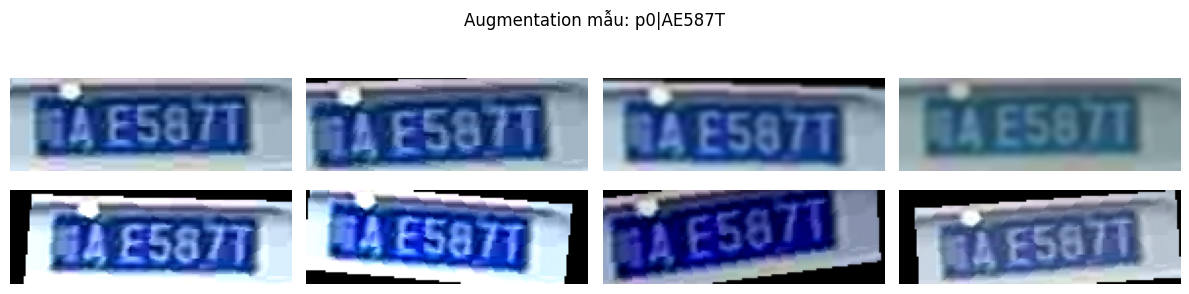

In [15]:
# Xem trước augmentation: cùng một crop qua TRAIN_TF 8 lần
if torch is not None and (DATA_ROOT/'labels.csv').is_file():
    import matplotlib.pyplot as plt
    r=LABELS[LABELS.split=='train'].iloc[0]; base=Image.open(DATA_ROOT/r.crop_rel).convert('RGB')
    fig,axes=plt.subplots(2,4,figsize=(12,3.2))
    for ax in axes.ravel():
        x=TRAIN_TF(base)*0.5+0.5; ax.imshow(x.permute(1,2,0).clamp(0,1).numpy()); ax.axis('off')
    plt.suptitle('Augmentation mẫu: '+ascii_label(r.text)); plt.tight_layout(); plt.show()

## 7. Mô hình
Cả hai trả về logit `[B, T, C]` (C = 1 blank + 67 ký tự). **E1** cho T=36, **E2** cho T=18. Các biến thể `VARIANTS` ứng với bảng ablation của paper (Bảng 8 Focus, Bảng 10 số head, Bảng 11 số decoding unit).

In [16]:
if torch is not None:
    def pe1d(n,d):
        pos=torch.arange(n,dtype=torch.float32).unsqueeze(1)
        div=torch.exp(torch.arange(0,d,2,dtype=torch.float32)*(-math.log(10000.0)/d))
        pe=torch.zeros(n,d); pe[:,0::2]=torch.sin(pos*div); pe[:,1::2]=torch.cos(pos*div); return pe
    def pe2d(c,h,w):
        ph,pw=pe1d(h,c//2),pe1d(w,c//2)
        pe=torch.cat([ph[:,None,:].expand(h,w,c//2),pw[None,:,:].expand(h,w,c//2)],dim=-1)
        return pe.permute(2,0,1).unsqueeze(0)

    class CNNBlock(nn.Module):       # theo Hình 3 của paper: LeakyReLU -> BatchNorm -> Conv
        def __init__(self,cin,cout,k=3,s=1,p=None):
            super().__init__()
            p=(k//2 if isinstance(k,int) else 0) if p is None else p
            self.act=nn.LeakyReLU(0.1); self.bn=nn.BatchNorm2d(cin); self.conv=nn.Conv2d(cin,cout,k,s,p,bias=False)
        def forward(self,x): return self.conv(self.bn(self.act(x)))
    class ResBlock(nn.Module):
        def __init__(self,c): super().__init__(); self.a=CNNBlock(c,c); self.b=CNNBlock(c,c)
        def forward(self,x): return x+self.b(self.a(x))
    class Focus(nn.Module):          # cắt lát 4 phần rồi nối theo kênh: 3x48x144 -> 12x24x72 -> conv
        def __init__(self,cin,cout): super().__init__(); self.conv=nn.Conv2d(cin*4,cout,3,1,1,bias=False)
        def forward(self,x):
            return self.conv(torch.cat([x[...,::2,::2],x[...,1::2,::2],x[...,::2,1::2],x[...,1::2,1::2]],dim=1))
    class IGFE(nn.Module):           # 3x48x144 -> 512x6x18
        def __init__(self,use_focus=True,ch=(64,128,512)):
            super().__init__()
            stem=Focus(3,ch[0]) if use_focus else nn.Conv2d(3,ch[0],3,2,1,bias=False)
            self.net=nn.Sequential(stem,ResBlock(ch[0]),ResBlock(ch[0]),CNNBlock(ch[0],ch[1],3,2,1),
                                   ResBlock(ch[1]),ResBlock(ch[1]),CNNBlock(ch[1],ch[2],3,2,1))
        def forward(self,x): return self.net(x)
    class EncUnit(nn.Module):
        def __init__(self,c=512,d=1024,heads=8,drop=0.1):
            super().__init__()
            self.cnn1=CNNBlock(c,d,1,1,0); self.mha=nn.MultiheadAttention(d,heads,dropout=drop,batch_first=True)
            self.cnn2=CNNBlock(d,c,1,1,0); self.norm=nn.LayerNorm(c)
        def forward(self,x):
            B,C,H,W=x.shape; y=self.cnn1(x); t=y.flatten(2).transpose(1,2)
            t,_=self.mha(t,t,t,need_weights=False)
            y=self.cnn2(t.transpose(1,2).reshape(B,-1,H,W))
            z=self.norm((x+y).flatten(2).transpose(1,2))
            return z.transpose(1,2).reshape(B,C,H,W)
    class DecUnit(nn.Module):
        def __init__(self,d=512,heads=8,ffn=512,drop=0.1):
            super().__init__()
            self.sa=nn.MultiheadAttention(d,heads,dropout=drop,batch_first=True); self.n1=nn.LayerNorm(d)
            self.ca=nn.MultiheadAttention(d,heads,dropout=drop,batch_first=True); self.n2=nn.LayerNorm(d)
            self.ffn=nn.Sequential(nn.Linear(d,ffn),nn.ReLU(),nn.Dropout(drop),nn.Linear(ffn,d)); self.n3=nn.LayerNorm(d)
        def forward(self,q,mem):
            q=self.n1(q+self.sa(q,q,q,need_weights=False)[0])
            q=self.n2(q+self.ca(q,mem,mem,need_weights=False)[0])
            return self.n3(q+self.ffn(q))

    class PDLPR(nn.Module):
        """PDLPR-inspired (xem các điểm khác paper ở đầu notebook). Đầu vào [B,3,48,144] -> logit [B,18,C]."""
        def __init__(self,num_classes,use_focus=True,n_enc=3,n_dec=3,heads=8,d_enc=1024,d_model=512,
                     n_queries=18,ffn=512,drop=0.1,query_mode='learned'):
            super().__init__()
            self.igfe=IGFE(use_focus); self.enc=nn.ModuleList([EncUnit(512,d_enc,heads,drop) for _ in range(n_enc)])
            self.reduce=nn.Sequential(nn.LeakyReLU(0.1),nn.BatchNorm2d(512),nn.Conv2d(512,d_model,(6,1),1,0,bias=False))
            self.query_mode=query_mode; self.n_queries=n_queries
            if query_mode=='learned': self.queries=nn.Parameter(torch.randn(n_queries,d_model)*0.02)
            self.dec=nn.ModuleList([DecUnit(d_model,heads,ffn,drop) for _ in range(n_dec)])
            self.head=nn.Linear(d_model,num_classes)
        def forward(self,x):
            f=self.igfe(x); assert f.shape[2]==6,'input phải cao 48 px'
            f=f+pe2d(f.size(1),f.size(2),f.size(3)).to(f.device,f.dtype)
            for u in self.enc: f=u(f)
            mem=self.reduce(f).squeeze(2).transpose(1,2)                         # [B,18,512]
            B,T,D=mem.shape; pe=pe1d(T,D).to(mem.device,mem.dtype)
            mem=mem+pe
            q=(mem if self.query_mode=='memory' else self.queries.unsqueeze(0).expand(B,-1,-1).to(mem.dtype)+
               pe1d(self.n_queries,D).to(mem.device,mem.dtype))
            for u in self.dec: q=u(q,mem)
            return self.head(q)                                                   # [B,T,C]

    class CRNN(nn.Module):
        """E1: CNN (VGG nhỏ) -> BiLSTM 2 lớp -> Linear. [B,3,48,144] -> logit [B,36,C]."""
        def __init__(self,num_classes,hidden=256,layers=2,drop=0.1):
            super().__init__()
            def blk(i,o): return nn.Sequential(nn.Conv2d(i,o,3,1,1,bias=False),nn.BatchNorm2d(o),nn.ReLU(True))
            self.cnn=nn.Sequential(blk(3,64),nn.MaxPool2d(2,2),blk(64,128),nn.MaxPool2d(2,2),
                blk(128,256),blk(256,256),nn.MaxPool2d((2,1),(2,1)),blk(256,512),blk(512,512),nn.MaxPool2d((2,1),(2,1)),
                nn.Conv2d(512,512,(3,1),1,0,bias=False),nn.BatchNorm2d(512),nn.ReLU(True))
            self.rnn=nn.LSTM(512,hidden,num_layers=layers,bidirectional=True,batch_first=True,dropout=drop)
            self.head=nn.Linear(2*hidden,num_classes)
        def forward(self,x):
            f=self.cnn(x).squeeze(2).transpose(1,2); o,_=self.rnn(f); return self.head(o)

    VARIANTS={
        'e1_crnn':          {'arch':'crnn','kw':{}},
        'e2_pdlpr':         {'arch':'pdlpr','kw':{}},
        'e2_pdlpr_nofocus': {'arch':'pdlpr','kw':{'use_focus':False}},   # ablation kiểu Bảng 8
        'e2_pdlpr_heads4':  {'arch':'pdlpr','kw':{'heads':4}},           # ablation kiểu Bảng 10
        'e2_pdlpr_dec1':    {'arch':'pdlpr','kw':{'n_dec':1}},           # ablation kiểu Bảng 11
        'e2_pdlpr_memq':    {'arch':'pdlpr','kw':{'query_mode':'memory'}},
    }
    def build_model(name):
        s=VARIANTS[name]; return (CRNN if s['arch']=='crnn' else PDLPR)(NUM_CLASSES,**s['kw'])
    def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

In [17]:
# Kiểm tra shape / backward / NaN bằng dữ liệu giả (không đụng dataset)
if torch is not None and RUN_MODEL_SELFTEST:
    ctc=nn.CTCLoss(blank=BLANK,zero_infinity=True)
    for name in VARIANTS:
        set_seed(SEED); m=build_model(name).train(); x=torch.randn(4,3,IMG_H,IMG_W)
        out=m(x); assert out.dim()==3 and out.size(0)==4 and out.size(2)==NUM_CLASSES,out.shape
        tgt=torch.randint(1,NUM_CLASSES,(4*7,)); tl=torch.full((4,),7,dtype=torch.long)
        loss=ctc(out.log_softmax(-1).permute(1,0,2),tgt,torch.full((4,),out.size(1),dtype=torch.long),tl)
        loss.backward(); assert torch.isfinite(loss),name
        print(f'{name:18s} out={tuple(out.shape)} params={count_params(m)/1e6:6.2f}M loss={loss.item():.2f}')
else: print('Self-test tắt hoặc thiếu torch.')

e1_crnn            out=(4, 36, 68) params=  8.48M loss=18.19
e2_pdlpr           out=(4, 18, 68) params= 26.67M loss=8.36
e2_pdlpr_nofocus   out=(4, 18, 68) params= 26.66M loss=9.03
e2_pdlpr_heads4    out=(4, 18, 68) params= 26.67M loss=8.87
e2_pdlpr_dec1      out=(4, 18, 68) params= 21.41M loss=8.76
e2_pdlpr_memq      out=(4, 18, 68) params= 26.66M loss=8.66


## 8. Huấn luyện và đánh giá
Loss CTC (blank=0), Adam lr=1e-3 như paper, `ReduceLROnPlateau` theo exact-match validation, early stopping, AMP, clip gradient 5. Mỗi epoch lưu `last.pt` nên có thể **resume** sau khi Colab ngắt (chạy lại cell train với cùng `TRAIN_LIST`). Chọn checkpoint theo validation; test chỉ chạy qua `TEST_LIST` một lần sau khi chốt.

In [26]:
# Siêu tham số riêng theo kiến trúc. E1 (crnn) giữ NGUYÊN như lần đã train; chỉ E2 (pdlpr) đổi.
HP={
 'crnn':  dict(lr=1e-3, opt='adam',  wd=0.0,  warmup_ep=0, epochs=EPOCHS, min_ep=0,  sched_start_ep=1, patience=EARLY_STOP_PATIENCE),
  'pdlpr': dict(lr=2e-4, opt='adamw', wd=1e-2, warmup_ep=3, epochs=40, min_ep=40, sched_start_ep=999, patience=EARLY_STOP_PATIENCE, cosine=True),
}
RESET_FAILED_RUNS=True    # run hỏng (best val_exact < 0.05) được đổi tên sang <tên>__failed_<giờ> rồi train lại từ đầu; run tốt không bao giờ bị động tới

if torch is not None:
    def make_optimizer(model,hp):
        if hp['opt']=='adamw': return torch.optim.AdamW(model.parameters(),lr=hp['lr'],betas=(0.9,0.98),weight_decay=hp['wd'])
        return torch.optim.Adam(model.parameters(),lr=hp['lr'])
    def apply_warmup(opt,hp,step,warm_steps,total_steps=None):
        if step<warm_steps: f=(step+1)/warm_steps
        elif hp.get('cosine') and total_steps:
            p=min((step-warm_steps)/max(1,total_steps-warm_steps),1.0); f=0.02+0.98*0.5*(1+math.cos(math.pi*p))
        else: return
        for g in opt.param_groups: g['lr']=hp['lr']*f
    print({k:{a:b for a,b in v.items() if a in ('lr','opt','warmup_ep','epochs')} for k,v in HP.items()})

{'crnn': {'lr': 0.001, 'opt': 'adam', 'warmup_ep': 0, 'epochs': 30}, 'pdlpr': {'lr': 0.0002, 'opt': 'adamw', 'warmup_ep': 3, 'epochs': 40}}


In [27]:
if torch is not None:
    AMP_ON=USE_AMP and DEVICE.type=='cuda'
    _ctc=nn.CTCLoss(blank=BLANK,zero_infinity=True)
    def ctc_loss(logits,tgt,tlen):
        lp=logits.float().log_softmax(-1).permute(1,0,2)
        return _ctc(lp,tgt,torch.full((logits.size(0),),logits.size(1),dtype=torch.long),tlen)
    def decode_batch(logits): return [ctc_collapse(r) for r in logits.argmax(-1).cpu().tolist()]

    @torch.no_grad()
    def evaluate(model,loader):
        model.eval(); tot=0.0; n=0; preds=[]
        for imgs,tgt,tlen,_ in loader:
            imgs=imgs.to(DEVICE,non_blocking=True)
            with torch.autocast('cuda',dtype=torch.float16,enabled=AMP_ON): logits=model(imgs)
            tot+=ctc_loss(logits,tgt.to(DEVICE),tlen).item()*imgs.size(0); n+=imgs.size(0); preds+=decode_batch(logits)
        return tot/max(n,1),preds

    def train_variant(name):
        hp=HP[VARIANTS[name]['arch']]; out=MODELS_DIR/name; out.mkdir(parents=True,exist_ok=True); set_seed(SEED)
        last=out/'last.pt'
        if RESET_FAILED_RUNS and last.is_file():          # run hỏng từ lần trước: lưu lại làm bằng chứng, train lại từ đầu
            ck0=torch.load(last,map_location='cpu',weights_only=False)
            if ck0.get('best',1.0)<0.05:
                old=MODELS_DIR/f"{name}__failed_{time.strftime('%Y%m%d_%H%M%S')}"; out.rename(old); out.mkdir(parents=True,exist_ok=True)
                print(f'[{name}] run cũ không hội tụ (best val_exact={ck0.get("best")}) -> đã lưu ở {old.name}, train lại từ đầu')
            del ck0
        df=LABELS; tr,va=df[df.split=='train'],df[df.split=='val']
        require(len(tr)>0 and len(va)>0,'Thiếu dữ liệu train/val')
        trl=make_loader(tr,True,limit=MAX_TRAIN_SAMPLES); val=make_loader(va,False)
        model=build_model(name).to(DEVICE)
        opt=make_optimizer(model,hp)
        sched=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='max',factor=0.5,patience=3)
        scaler=torch.amp.GradScaler('cuda',enabled=AMP_ON)
        hist=[]; best=-1.0; best_ep=0; start=1
        if last.is_file():
            ck=torch.load(last,map_location=DEVICE,weights_only=False)
            model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt']); sched.load_state_dict(ck['sched'])
            hist,best,best_ep,start=ck['hist'],ck['best'],ck['best_ep'],ck['epoch']+1; print(f'[{name}] resume từ epoch {start}')
        warm_steps=hp['warmup_ep']*len(trl); gstep=(start-1)*len(trl)
        print(f'[{name}] params={count_params(model)/1e6:.2f}M train={len(trl.dataset)} val={len(val.dataset)} | {hp["opt"]} lr={hp["lr"]} warmup={hp["warmup_ep"]}ep epochs={hp["epochs"]}')
        for ep in range(start,hp['epochs']+1):
            if ep>hp['min_ep'] and best_ep>0 and ep-best_ep>hp['patience']: print(f'[{name}] early stop tại epoch {ep-1}'); break
            model.train(); t0=time.time(); run=0.0; n=0
            for imgs,tgt,tlen,_ in trl:
                apply_warmup(opt,hp,gstep,warm_steps,hp['epochs']*len(trl)); gstep+=1
                imgs=imgs.to(DEVICE,non_blocking=True); tgt=tgt.to(DEVICE)
                opt.zero_grad(set_to_none=True)
                with torch.autocast('cuda',dtype=torch.float16,enabled=AMP_ON): logits=model(imgs)
                loss=ctc_loss(logits,tgt,tlen)
                scaler.scale(loss).backward(); scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(model.parameters(),5.0); scaler.step(opt); scaler.update()
                run+=loss.item()*imgs.size(0); n+=imgs.size(0)
            vloss,vp=evaluate(model,val); vm,_=compute_metrics(vp,va.text.tolist())
            if ep>=hp['sched_start_ep']: sched.step(vm['exact'])      # không giảm lr khi mô hình còn đang thoát khỏi plateau ban đầu
            rec={'epoch':ep,'train_loss':run/max(n,1),'val_loss':vloss,'val_exact':vm['exact'],'val_exact_no_province':vm['exact_no_province'],
                 'val_char_acc':vm['char_acc'],'lr':opt.param_groups[0]['lr'],'sec':time.time()-t0}
            hist.append(rec)
            if vm['exact']>best: best,best_ep=vm['exact'],ep; torch.save({'model':model.state_dict(),'epoch':ep,'val_exact':best,'name':name},out/'best.pt')
            torch.save({'model':model.state_dict(),'opt':opt.state_dict(),'sched':sched.state_dict(),'epoch':ep,'hist':hist,'best':best,'best_ep':best_ep},last)
            pd.DataFrame(hist).to_csv(out/'history.csv',index=False)
            print(f"[{name}] ep{ep:02d} loss {rec['train_loss']:.3f}/{vloss:.3f} val_exact {vm['exact']:.4f} (no_prov {vm['exact_no_province']:.4f}) lr {rec['lr']:.1e} {rec['sec']:.0f}s")
        return {'best_val_exact':best,'best_epoch':best_ep,'epochs_run':len(hist)}

    TRAIN_SUMMARY={}
    if TRAIN_LIST:
        LABELS=load_labels()
        for nm in TRAIN_LIST:
            require(nm in VARIANTS,f'Không có biến thể {nm}'); TRAIN_SUMMARY[nm]=train_variant(nm)
        print(json.dumps(TRAIN_SUMMARY,indent=2))
    else: print('TRAIN_LIST rỗng: chưa huấn luyện gì.')

[e2_pdlpr] params=26.67M train=18000 val=2000 | adamw lr=0.0002 warmup=3ep epochs=40
[e2_pdlpr] ep01 loss 3.863/2.585 val_exact 0.0000 (no_prov 0.0000) lr 6.7e-05 28s
[e2_pdlpr] ep02 loss 2.273/1.102 val_exact 0.0330 (no_prov 0.0335) lr 1.3e-04 27s
[e2_pdlpr] ep03 loss 0.543/0.212 val_exact 0.6415 (no_prov 0.6605) lr 2.0e-04 27s
[e2_pdlpr] ep04 loss 0.168/0.092 val_exact 0.8465 (no_prov 0.8660) lr 2.0e-04 28s
[e2_pdlpr] ep05 loss 0.112/0.064 val_exact 0.8835 (no_prov 0.9060) lr 2.0e-04 27s
[e2_pdlpr] ep06 loss 0.082/0.071 val_exact 0.9005 (no_prov 0.9130) lr 2.0e-04 27s
[e2_pdlpr] ep07 loss 0.076/0.038 val_exact 0.9360 (no_prov 0.9530) lr 1.9e-04 28s
[e2_pdlpr] ep08 loss 0.065/0.033 val_exact 0.9560 (no_prov 0.9660) lr 1.9e-04 27s
[e2_pdlpr] ep09 loss 0.048/0.022 val_exact 0.9620 (no_prov 0.9710) lr 1.9e-04 27s
[e2_pdlpr] ep10 loss 0.044/0.031 val_exact 0.9480 (no_prov 0.9590) lr 1.8e-04 27s
[e2_pdlpr] ep11 loss 0.039/0.023 val_exact 0.9565 (no_prov 0.9625) lr 1.8e-04 27s
[e2_pdlpr] ep

In [28]:
# Smoke test: overfit 256 mẫu, không augmentation, dùng ĐÚNG optimizer/lr/warmup như khi train thật.
# Mốc tham chiếu E1 (đã train tốt): loss ~2.8 ở bước 50 -> ~1.8 ở bước 300. E2 phải giảm tương đương hoặc nhanh hơn.
SMOKE_STEPS=400; SMOKE_WARM=60
if torch is not None and RUN_SMOKE_TEST:
    def load_labels_local():
        p=DATA_ROOT/'labels.csv'
        if not p.is_file():
            raise RuntimeError(f'Chưa có {p}. Bật RUN_BUILD_CROPS và chạy cell dựng crop.')
        return pd.read_csv(p,encoding='utf-8-sig',dtype={'text':str})

    LABELS=load_labels_local(); sm=LABELS[LABELS.split=='train'].sample(256,random_state=SEED)
    for nm in SMOKE_MODELS:
        hp=HP[VARIANTS[nm]['arch']]
        set_seed(SEED); m=build_model(nm).to(DEVICE).train(); opt=make_optimizer(m,hp)
        ld=make_loader(sm,True,batch_size=64,tf=EVAL_TF); step=0; t0=time.time(); first=None
        while step<SMOKE_STEPS:
            for imgs,tgt,tlen,_ in ld:
                apply_warmup(opt,hp,step,SMOKE_WARM)
                opt.zero_grad(); loss=ctc_loss(m(imgs.to(DEVICE)),tgt.to(DEVICE),tlen); loss.backward()
                nn.utils.clip_grad_norm_(m.parameters(),5.0); opt.step(); step+=1
                if step==50: first=loss.item()
                if step%50==0: print(f'[{nm}] step {step} loss {loss.item():.3f}')
                if step>=SMOKE_STEPS: break
        ld_e=make_loader(sm,False,tf=EVAL_TF); _,p=evaluate(m,ld_e); acc,_=compute_metrics(p,sm.text.tolist())
        print(f'[{nm}] loss bước 50 -> {SMOKE_STEPS}: {first:.3f} -> {loss.item():.3f} | exact 256 mẫu train: {acc["exact"]:.3f} ({time.time()-t0:.0f}s)')
else: print('Smoke test tắt.')

[e2_pdlpr] step 50 loss 1.840
[e2_pdlpr] step 100 loss 1.216
[e2_pdlpr] step 150 loss 0.844
[e2_pdlpr] step 200 loss 0.494
[e2_pdlpr] step 250 loss 0.250
[e2_pdlpr] step 300 loss 0.174
[e2_pdlpr] step 350 loss 0.128
[e2_pdlpr] step 400 loss 0.129
[e2_pdlpr] loss bước 50 -> 400: 1.840 -> 0.129 | exact 256 mẫu train: 0.945 (63s)
[e2_pdlpr_memq] step 50 loss 1.600
[e2_pdlpr_memq] step 100 loss 0.514
[e2_pdlpr_memq] step 150 loss 0.018
[e2_pdlpr_memq] step 200 loss 0.033
[e2_pdlpr_memq] step 250 loss 0.032
[e2_pdlpr_memq] step 300 loss 0.032
[e2_pdlpr_memq] step 350 loss 0.005
[e2_pdlpr_memq] step 400 loss 0.017
[e2_pdlpr_memq] loss bước 50 -> 400: 1.600 -> 0.017 | exact 256 mẫu train: 0.984 (63s)


## 9. Đánh giá test cuối, phân rã theo subset và đo tốc độ
Chỉ chạy mô hình trong `TEST_LIST`. Tốc độ đo forward của recognizer (batch 1 và 64, đã khởi động, có `synchronize`), không gồm đọc file/tiền xử lý CPU; chỉ dùng để so sánh nội bộ.

In [32]:
if torch is not None:
    def load_best(name):
        m=build_model(name).to(DEVICE); ck=torch.load(MODELS_DIR/name/'best.pt',map_location=DEVICE,weights_only=False)
        m.load_state_dict(ck['model']); return m.eval(),ck
    @torch.no_grad()
    def measure_speed(model,bs,iters=100,warm=10):
        x=torch.randn(bs,3,IMG_H,IMG_W,device=DEVICE)
        for _ in range(warm):
            with torch.autocast('cuda',dtype=torch.float16,enabled=AMP_ON): model(x)
        if DEVICE.type=='cuda': torch.cuda.synchronize()
        t0=time.perf_counter()
        for _ in range(iters):
            with torch.autocast('cuda',dtype=torch.float16,enabled=AMP_ON): decode_batch(model(x))
        if DEVICE.type=='cuda': torch.cuda.synchronize()
        return bs*iters/(time.perf_counter()-t0)
    def run_test(name):
        LAB=load_labels(); te=LAB[LAB.split=='test'].reset_index(drop=True); require(len(te)>0,'Không có mẫu test')
        model,ck=load_best(name); _,preds=evaluate(model,make_loader(te,False))
        met,by=compute_metrics(preds,te.text.tolist(),te.subset.tolist())
        speed={'bs1_img_per_s':measure_speed(model,1),'bs64_img_per_s':measure_speed(model,64)}
        RESULTS_DIR.mkdir(parents=True,exist_ok=True)
        pd.DataFrame({'crop_rel':te.crop_rel,'subset':te.subset,'gt':te.text,'pred':preds,'correct':[p==g for p,g in zip(preds,te.text)]}).to_csv(RESULTS_DIR/f'{name}_test_preds.csv',index=False,encoding='utf-8-sig')
        history_path=MODELS_DIR/name/'history.csv'
        epochs_run=int(pd.read_csv(history_path)['epoch'].max()) if history_path.is_file() else None
        res={'name':name,'arch':VARIANTS[name]['arch'],'params':count_params(model),'test':met,'by_subset':by,'speed':speed,
             'best_epoch':ck.get('epoch'),'best_val_exact':ck.get('val_exact'),'device':str(DEVICE),
             'gpu':torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else None,'crop_margin':CROP_MARGIN,'seed':SEED,
             'epochs_cfg':HP[VARIANTS[name]['arch']]['epochs'],'epochs_run':epochs_run,
             'test_protocol':{'metric':'recognition_exact_match','input':'ground-truth YOLO-label crop','crop_margin':CROP_MARGIN,'test_samples':len(te)}}
        (RESULTS_DIR/f'{name}.json').write_text(json.dumps(res,ensure_ascii=False,indent=2)); return res
    if TEST_LIST:
        for nm in TEST_LIST:
            r=run_test(nm); print(nm,json.dumps({k:r[k] for k in ('params','test','speed')},ensure_ascii=False,indent=1))
    else: print('TEST_LIST rỗng: chưa chạy test. Chốt model theo validation rồi điền danh sách.')

e1_crnn {
 "params": 8478852,
 "test": {
  "n": 5000,
  "exact": 0.5554,
  "exact_no_province": 0.6088,
  "province_acc": 0.9312,
  "char_acc": 0.8925714285714286
 },
 "speed": {
  "bs1_img_per_s": 198.96980716207375,
  "bs64_img_per_s": 8536.60831774152
 }
}
e2_pdlpr {
 "params": 26669764,
 "test": {
  "n": 5000,
  "exact": 0.6288,
  "exact_no_province": 0.6714,
  "province_acc": 0.9436,
  "char_acc": 0.9105428571428571
 },
 "speed": {
  "bs1_img_per_s": 89.60207440981762,
  "bs64_img_per_s": 3524.0451841577856
 }
}
e2_pdlpr_memq {
 "params": 26660548,
 "test": {
  "n": 5000,
  "exact": 0.6254,
  "exact_no_province": 0.6698,
  "province_acc": 0.9406,
  "char_acc": 0.9114857142857142
 },
 "speed": {
  "bs1_img_per_s": 95.6942267825407,
  "bs64_img_per_s": 3663.468371200062
 }
}


## 10. So sánh E1 vs E2 và phân tích lỗi
Bảng tổng hợp đọc từ `results/*.json` (chỉ có số thật từ các lần chạy). Phân tích lỗi đọc file dự đoán test, nhóm theo vị trí ký tự và cặp nhầm lẫn.

,params_M,exact,exact_no_province,province_acc,char_acc,img/s bs1,img/s bs64
model,,,,,,,
e1_crnn,8.48,0.5554,0.6088,0.9312,0.8926,199.0,8536.6
e2_pdlpr,26.67,0.6288,0.6714,0.9436,0.9105,89.6,3524.0
e2_pdlpr_memq,26.66,0.6254,0.6698,0.9406,0.9115,95.7,3663.5


,e1_crnn,e2_pdlpr,e2_pdlpr_memq
blur,0.5000,0.6120,0.6060
challenge,0.5984,0.6924,0.6832
db,0.5160,0.6160,0.5980
fn,0.5600,0.6000,0.6100
rotate,0.5580,0.5580,0.5860
tilt,0.4280,0.4400,0.4380


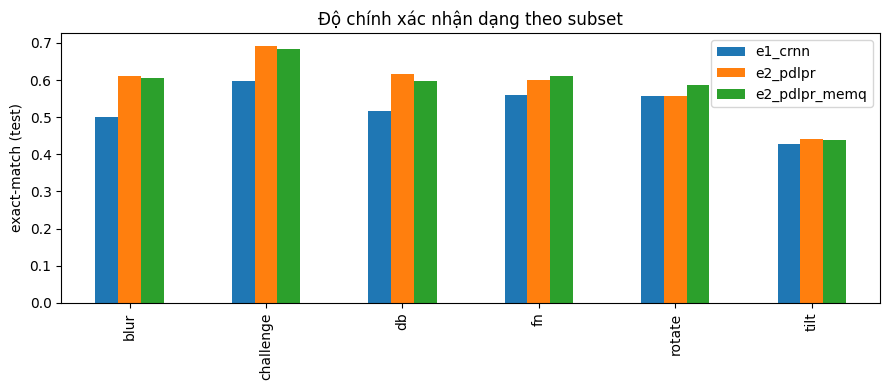


e1_crnn_test_preds: 2223 lỗi | theo vị trí: {0: 327, 1: 132, 2: 610, 3: 549, 4: 424, 5: 424, 6: 587, 'length': 253} | nhầm nhiều nhất: [(('0', 'D'), 127), (('5', 'S'), 53), (('B', '8'), 48), (('A', '4'), 48), (('5', '3'), 46), (('9', '8'), 46), (('1', '7'), 43), (('T', '7'), 39)]

e2_pdlpr_memq_test_preds: 1873 lỗi | theo vị trí: {0: 275, 1: 89, 2: 478, 3: 377, 4: 342, 5: 303, 6: 401, 'length': 359} | nhầm nhiều nhất: [(('0', 'D'), 47), (('B', '8'), 36), (('D', '0'), 35), (('9', '8'), 31), (('S', '5'), 27), (('6', '8'), 26), (('陕', '皖'), 25), (('0', '2'), 23)]

e2_pdlpr_test_preds: 1856 lỗi | theo vị trí: {0: 274, 1: 98, 2: 553, 3: 496, 4: 428, 5: 455, 6: 525, 'length': 137} | nhầm nhiều nhất: [(('6', '8'), 64), (('7', '2'), 47), (('D', '0'), 44), (('0', 'D'), 43), (('0', '8'), 41), (('0', '2'), 40), (('B', '8'), 35), (('Z', '2'), 34)]


In [33]:
res_files=[p for p in sorted(RESULTS_DIR.glob('*.json')) if not p.name.startswith('e2e_')] if RESULTS_DIR.is_dir() else []
if res_files:
    R=[json.loads(p.read_text()) for p in res_files]
    tab=pd.DataFrame([{'model':r['name'],'params_M':round(r['params']/1e6,2),'exact':r['test']['exact'],'exact_no_province':r['test']['exact_no_province'],
        'province_acc':r['test']['province_acc'],'char_acc':r['test']['char_acc'],'img/s bs1':round(r['speed']['bs1_img_per_s'],1),'img/s bs64':round(r['speed']['bs64_img_per_s'],1)} for r in R]).set_index('model')
    display(tab.round(4)); tab.to_csv(RESULTS_DIR/'comparison_overall.csv',encoding='utf-8-sig')
    sub=pd.DataFrame({r['name']:{s:v['exact'] for s,v in r['by_subset'].items()} for r in R}); display(sub.round(4)); sub.to_csv(RESULTS_DIR/'comparison_by_subset.csv',encoding='utf-8-sig',index_label='subset')
    import matplotlib.pyplot as plt
    ax=sub.plot.bar(figsize=(9,4)); ax.set_ylabel('exact-match (test)'); ax.set_title('Độ chính xác nhận dạng theo subset'); plt.tight_layout(); plt.show()
else: print('Chưa có results/*.json.')
for p in sorted(RESULTS_DIR.glob('*_test_preds.csv')) if RESULTS_DIR.is_dir() else []:
    d=pd.read_csv(p,encoding='utf-8-sig',dtype=str); d=d[d['gt']!=d['pred']]
    pos=Counter(); pairs=Counter()
    for g,pr in zip(d['gt'],d['pred'].fillna('')):
        if len(g)==len(pr):
            for i,(a,b) in enumerate(zip(g,pr)):
                if a!=b: pos[i]+=1; pairs[(a,b)]+=1
        else: pos['length']+=1
    print(f'\n{p.stem}: {len(d)} lỗi | theo vị trí: {dict(sorted(pos.items(),key=lambda kv:str(kv[0])))} | nhầm nhiều nhất: {pairs.most_common(8)}')

## 11. Pipeline end-to-end: detector E0 + recognizer (opt-in)
Chạy YOLOv5s của E0 trên ảnh test gốc, cắt box dự đoán (cùng `CROP_MARGIN`), rồi nhận dạng bằng từng mô hình. Dùng tiêu chí của paper: **đúng khi IoU > 0.6 với box GT và đúng mọi ký tự**. Cũng báo độ chính xác detection (IoU > 0.7) và độ chính xác nhận dạng khi detection đúng. Ảnh gốc đọc từ `DATASET_DIR` (local), box GT từ `labels.csv` (cùng nguồn label của E0). Cần `best.pt` của E0 (tự tìm ở `/content/outputs/...` hoặc Drive); repo YOLOv5 tự clone nếu chưa có; không train gì thêm.

In [34]:
if torch is not None and RUN_E2E:
    E0_BEST_PT=resolve_e0_best()
    require(E0_BEST_PT.is_file(),'Không thấy best.pt của E0 ở: '+', '.join(map(str,E0_BEST_PT_CANDIDATES))+'. Copy file từ phiên E0 (hoặc từ Drive) rồi chạy lại.')
    if not (YOLOV5_DIR/'hubconf.py').is_file():     # phiên Colab mới: dựng lại repo YOLOv5 như E0
        subprocess.run(['git','clone','https://github.com/ultralytics/yolov5.git',str(YOLOV5_DIR)],check=True)
        subprocess.run([sys.executable,'-m','pip','install','-q','-r',str(YOLOV5_DIR/'requirements.txt')],check=True)
    print('Detector E0:',E0_BEST_PT)
    LAB=load_labels(); te=LAB[LAB.split=='test']; meta=json.loads((DATA_ROOT/'crops_meta.json').read_text()); margin=meta['margin']
    if E2E_MAX_PER_SUBSET: te=te.groupby('subset',group_keys=False).apply(lambda g:g.sample(min(E2E_MAX_PER_SUBSET,len(g)),random_state=SEED))
    det=torch.hub.load(str(YOLOV5_DIR),'custom',path=str(E0_BEST_PT),source='local',trust_repo=True); det.conf=0.25; det.iou=0.45; det.to(DEVICE)
    loaded_recs={n:load_best(n) for n in E2E_MODELS}; recs={n:v[0] for n,v in loaded_recs.items()}; rows=[]
    def sync():
        if DEVICE.type=='cuda': torch.cuda.synchronize()
    for k,(_,r) in enumerate(te.iterrows()):
        img=np.array(Image.open(DATASET_DIR/r.src_rel).convert('RGB')); h,w=img.shape[:2]; gt=(r.x1,r.y1,r.x2,r.y2)
        sync(); t0=time.perf_counter(); pr=det(img,size=640).xyxy[0].detach().cpu().tolist(); sync(); t_det=(time.perf_counter()-t0)*1000
        top=max(pr,key=lambda q:q[4]) if pr else None; iou=box_iou_xyxy(top[:4],gt) if top else 0.0
        row={'crop_rel':r.crop_rel,'subset':r.subset,'gt':r.text,'iou':iou,'det_ms':t_det}
        if top:
            x=EVAL_TF(Image.fromarray(img).crop(crop_box(top[:4],w,h,margin))).unsqueeze(0).to(DEVICE)
            for n,m in recs.items():
                sync(); t1=time.perf_counter()
                with torch.no_grad(), torch.autocast('cuda',dtype=torch.float16,enabled=AMP_ON): txt=decode_batch(m(x))[0]
                sync(); row[f'{n}_pred']=txt; row[f'{n}_ms']=(time.perf_counter()-t1)*1000
        rows.append(row)
    E=pd.DataFrame(rows); RESULTS_DIR.mkdir(parents=True,exist_ok=True); E.to_csv(RESULTS_DIR/'e2e_per_image.csv',index=False,encoding='utf-8-sig')
    summ={'images':len(E),'det_acc_iou07':float((E['iou']>IOU_DET).mean()),'det_only_fps':float(1000/E.det_ms.mean())}
    for n in E2E_MODELS:
        if f'{n}_pred' not in E: continue
        okp=E[f'{n}_pred'].fillna('')==E['gt']; ok=(E['iou']>IOU_E2E)&okp; ms=E.det_ms+E[f'{n}_ms'].fillna(0)
        summ[n]={'e2e_acc':float(ok.mean()),'recog_acc_when_det_ok':float(okp[E['iou']>IOU_DET].mean()),'e2e_fps':float(1000/ms.mean()),
                 'by_subset':{s:float(ok[E.subset==s].mean()) for s in sorted(E.subset.unique())}}
        (RESULTS_DIR/f'e2e_{n}.json').write_text(json.dumps({'name':n,**summ[n],'det_acc_iou07':summ['det_acc_iou07'],'iou_e2e':IOU_E2E,
            'test_samples':len(E),'metric_definition':'fraction of all test samples with IoU > iou_e2e and exact text match',
            'detector_confidence_threshold':0.25,'detector_nms_iou':0.45,'detector_image_size':640,'crop_margin':margin,
            'detector_checkpoint_path':str(E0_BEST_PT),
            'recognizer_checkpoint':{'best_epoch':loaded_recs[n][1].get('epoch'),'best_val_exact':loaded_recs[n][1].get('val_exact')}},indent=2))
    print(json.dumps(summ,ensure_ascii=False,indent=2))
else: print('E2E tắt. Đặt RUN_E2E=True sau khi đã có E0 best.pt và checkpoint E1/E2.')

Detector E0: /content/drive/MyDrive/ComputerVision/A2/outputs/yolov5s_e0/runs/yolov5s_ccpd_e0/weights/best.pt
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLOv5 🚀 v7.0-570-gcb2f17fd Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)

Fusing layers... 
Model summary: 68 layers, 7,012,822 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
{
  "images": 5000,
  "det_acc_iou07": 0.8802,
  "det_only_fps": 82.34527309042956,
  "e1_crnn": {
    "e2e_acc": 0.5554,
    "recog_acc_when_det_ok": 0.5907748239036582,
    "e2e_fps": 56.6121902747277,
    "by_subset": {
      "blur": 0.452,
      "challenge": 0.578,
      "db": 0.45,
      "fn": 0.6,
      "rotate": 0.614,
      "tilt": 0.548
    }
  },
  "e2_pdlpr": {
    "e2e_acc": 0.65

In [35]:
import shutil
from pathlib import Path

# Xác định các đường dẫn lưu trữ
local_output_dir = Path('/content/outputs')
local_crops_dir = Path('/content/plate_crops')
drive_backup_dir = DRIVE_PROJECT / 'backups'
drive_backup_dir.mkdir(parents=True, exist_ok=True)

print("=== BẮT ĐẦU SAO LƯU KẾT QUẢ LÊN GOOGLE DRIVE ===")

# 1. Sao lưu thư mục plate_crops dưới dạng file nén zip nếu tồn tại
if local_crops_dir.exists():
    zip_path = drive_backup_dir / 'plate_crops_backup'
    print(f"Đang nén và sao lưu {local_crops_dir} -> {zip_path}.zip...")
    shutil.make_archive(str(zip_path), 'zip', local_crops_dir)
    print("Đã sao lưu thành công plate_crops!")
else:
    print("Không tìm thấy thư mục plate_crops cục bộ.")

# 2. Sao lưu thư mục local outputs (nếu có lưu trữ tạm thời ở /content/outputs)
if local_output_dir.exists():
    zip_out_path = drive_backup_dir / 'local_outputs_backup'
    print(f"Đang nén và sao lưu {local_output_dir} -> {zip_out_path}.zip...")
    shutil.make_archive(str(zip_out_path), 'zip', local_output_dir)
    print("Đã sao lưu thành công local outputs!")
else:
    print("Không tìm thấy thư mục /content/outputs cục bộ.")

# 3. Đồng bộ thư mục kết quả recognition trực tiếp lên Drive
if RESULTS_DIR.exists():
    print(f"Thư mục kết quả hiện tại đã được lưu ở Drive: {RESULTS_DIR}")
    print("Danh sách các file kết quả đang có trên Drive:")
    for f in RESULTS_DIR.glob('*'):
        print(f" - {f.name}")
else:
    print("Chưa có thư mục kết quả kiểm thử.")

print("\n=== HOÀN THÀNH SAO LƯU ===")

=== BẮT ĐẦU SAO LƯU KẾT QUẢ LÊN GOOGLE DRIVE ===
Đang nén và sao lưu /content/plate_crops -> /content/drive/MyDrive/ComputerVision/A2/backups/plate_crops_backup.zip...
Đã sao lưu thành công plate_crops!
Không tìm thấy thư mục /content/outputs cục bộ.
Thư mục kết quả hiện tại đã được lưu ở Drive: /content/drive/MyDrive/ComputerVision/A2/outputs/recognition_e1_e2/results
Danh sách các file kết quả đang có trên Drive:
 - e1_crnn_test_preds.csv
 - e1_crnn.json
 - e2_pdlpr_test_preds.csv
 - e2_pdlpr.json
 - comparison_overall.csv
 - comparison_by_subset.csv
 - e2e_per_image.csv
 - e2e_e1_crnn.json
 - e2e_e2_pdlpr.json
 - e2_pdlpr_memq_test_preds.csv
 - e2_pdlpr_memq.json
 - e2e_e2_pdlpr_memq.json

=== HOÀN THÀNH SAO LƯU ===


## 12. Checklist bàn giao E1/E2 và liên hệ paper
- [ ] Chạy bảng parse tên file (≥ 99%), dựng crop, ghi số mẫu/subset và tỉ lệ ký tự tỉnh "皖" vào báo cáo.
- [ ] Copy `best.pt` của E0 từ `/content/outputs/yolov5s_e0/...` lên Drive (E0 đang ghi local, mất khi ngắt phiên).
- [ ] Chạy `RUN_SMOKE_TEST` cho cả hai mô hình trước khi train dài; nếu E2 không hội tụ, thử `e2_pdlpr_memq`.
- [ ] Train E1 và E2 cùng cấu hình; lưu `history.csv` để vẽ đường cong loss/exact.
- [ ] Chọn checkpoint theo validation, **rồi mới** điền `TEST_LIST`; không dùng test để tuning.
- [ ] Báo cáo exact-match, exact-match không tính ký tự tỉnh, char accuracy, số tham số, img/s (bs1, bs64) cho E1 vs E2.
- [ ] (Mở rộng) Train 1–2 biến thể ablation (`e2_pdlpr_nofocus`, `e2_pdlpr_dec1`, `e2_pdlpr_heads4`) và đối chiếu với xu hướng ở Bảng 8, 10, 11 của paper; nếu ngược xu hướng thì giải thích (ít dữ liệu, ít epoch, khác lựa chọn cài đặt).
- [ ] Chạy E2E, báo cáo theo tiêu chí paper (IoU > 0.6 và đúng mọi ký tự) cùng độ chính xác detection IoU > 0.7.
- [ ] Trong phần phân tích paper, nói rõ: các điểm E2 khác paper (đầu notebook), mâu thuẫn CTC với "shifted right" của decoder, giả thiết train chỉ trên CCPD (miền biển số Trung Quốc, 皖 chiếm hơn 95%) nên chuyển sang biển số khác kém. Không tuyên bố đã reproduce PDLPR hay so sánh con số trực tiếp với 99.4% / 159.8 FPS của paper.
- [ ] Đưa code, PDF, GitHub Pages và video demo theo mục 7 của đề.

**Tham chiếu:** Assignment 2 CO5085; Tao et al., *Sensors* 24 (2024), 2791, DOI 10.3390/s24092791.